In [1]:
# Set Dataset
# Roll number = p26ai0008

import numpy as np
from sklearn.datasets import fetch_olivetti_faces

faces = fetch_olivetti_faces()
X = faces.data
y = faces.target

rng = np.random.default_rng(260008) # set the seed value

train_idx, val_idx, test_idx = [], [], []

# spliting the dataset in training , validation and testing data set
for identity in np.unique(y):
    idx = np.where(y == identity)[0]
    rng.shuffle(idx)

    train_idx.extend(idx[:6])
    val_idx.extend(idx[6:8])
    test_idx.extend(idx[8:])

train_idx = np.array(train_idx)
val_idx = np.array(val_idx)
test_idx = np.array(test_idx)

# save the training , valdation and testing data set
np.savez("olivetti_split.npz",
         train_idx=train_idx,
         val_idx=val_idx,
         test_idx=test_idx)

In [2]:
# print the datasets sizes
print("Train:", len(train_idx))
print("Validation:", len(val_idx))
print("Test:", len(test_idx))

Train: 240
Validation: 80
Test: 80


In [3]:
# New test set for robustness
X_test_robust = X[test_idx].reshape(-1, 64, 64).copy()
X_test_robust[:, 24:40, 24:40] = 0
X_test_robust = X_test_robust.reshape(-1, 4096)

# Q1. Decision tree baseline and bagging from scratch

In [4]:
#Part(a)
from sklearn.tree import DecisionTreeClassifier

depths =[2, 4, 8, 16, None]
leaf_sizes =  [1, 2, 4]

for depth in depths:
    for leaf in leaf_sizes:
        model = DecisionTreeClassifier(max_depth=depth,
                                       min_samples_leaf=leaf,
                                       random_state=260008)
        model.fit(X[train_idx], y[train_idx])
        print("max_depth:", depth, "min_samples_leaf:", leaf)

max_depth: 2 min_samples_leaf: 1
max_depth: 2 min_samples_leaf: 2
max_depth: 2 min_samples_leaf: 4
max_depth: 4 min_samples_leaf: 1
max_depth: 4 min_samples_leaf: 2
max_depth: 4 min_samples_leaf: 4
max_depth: 8 min_samples_leaf: 1
max_depth: 8 min_samples_leaf: 2
max_depth: 8 min_samples_leaf: 4
max_depth: 16 min_samples_leaf: 1
max_depth: 16 min_samples_leaf: 2
max_depth: 16 min_samples_leaf: 4
max_depth: None min_samples_leaf: 1
max_depth: None min_samples_leaf: 2
max_depth: None min_samples_leaf: 4


In [5]:
depths = [2, 4, 8, 16, None]
leaf_sizes = [1, 2, 4]

best_val_acc = -1

for depth in depths:
    for leaf in leaf_sizes:
        model = DecisionTreeClassifier(max_depth=depth,
                                       min_samples_leaf=leaf,
                                       random_state=260008)
        model.fit(X[train_idx], y[train_idx])

        val_acc = np.mean(model.predict(X[val_idx]) == y[val_idx])

        if val_acc > best_val_acc:
            best_val_acc = val_acc
            best_depth = depth
            best_min_leaf = leaf
            frozen_tree = model

tree_depth_frozen = best_depth
tree_min_leaf_frozen = best_min_leaf

train_acc = np.mean(frozen_tree.predict(X[train_idx]) == y[train_idx])
val_acc = np.mean(frozen_tree.predict(X[val_idx]) == y[val_idx])
test_acc = np.mean(frozen_tree.predict(X[test_idx]) == y[test_idx])

tree = frozen_tree.tree_
leaves = np.where(tree.children_left == -1)[0]
samples = tree.n_node_samples[leaves]

print("Best max_depth:", best_depth)
print("Best min_samples_leaf:", best_min_leaf)
print("Train accuracy:", train_acc)
print("Val accuracy:", val_acc)
print("Test accuracy:", test_acc)
print("No. of leaves:", len(leaves))
print("Mean samples per leaf:", np.mean(samples))
print("Fraction of leaves with one training example:", np.mean(samples == 1))

Best max_depth: None
Best min_samples_leaf: 1
Train accuracy: 1.0
Val accuracy: 0.6125
Test accuracy: 0.5875
No. of leaves: 42
Mean samples per leaf: 5.714285714285714
Fraction of leaves with one training example: 0.047619047619047616


In [6]:
# Part (b)
# Bagging

B_values = [1, 5, 10, 25, 50, 100, 200]
rng = np.random.default_rng(260008)

X_train, y_train = X[train_idx], y[train_idx]
X_val, y_val = X[val_idx], y[val_idx]
X_test, y_test = X[test_idx], y[test_idx]

trees = []
bootstrap_indices = []
distinct_counts = []

for b in range(200):
    sample_idx = rng.choice(len(X_train), len(X_train), replace=True)

    tree = DecisionTreeClassifier(
        max_depth=tree_depth_frozen,
        min_samples_leaf=tree_min_leaf_frozen,
        random_state=260008 + b
    )
    tree.fit(X_train[sample_idx], y_train[sample_idx])

    trees.append(tree)
    bootstrap_indices.append(sample_idx)
    distinct_counts.append(len(np.unique(sample_idx)))


def majority_vote(predictions):
    return np.array([
        np.bincount(predictions[:, i], minlength=40).argmax()
        for i in range(predictions.shape[1])
    ])


for B in B_values:
    train_pred = majority_vote(np.array([
        tree.predict(X_train) for tree in trees[:B]
    ]))
    val_pred = majority_vote(np.array([
        tree.predict(X_val) for tree in trees[:B]
    ]))
    test_pred = majority_vote(np.array([
        tree.predict(X_test) for tree in trees[:B]
    ]))

    print(
        "B:", B,
        "| Train:", np.mean(train_pred == y_train),
        "| Validation:", np.mean(val_pred == y_val),
        "| Test:", np.mean(test_pred == y_test),
        "| Avg distinct:", np.mean(distinct_counts[:B])
    )

n = len(X_train)
expected_distinct = n * (1 - (1 - 1/n)**n)

print("Theoretical expected distinct examples:", expected_distinct)

B: 1 | Train: 0.7458333333333333 | Validation: 0.35 | Test: 0.3125 | Avg distinct: 150.0
B: 5 | Train: 0.9666666666666667 | Validation: 0.625 | Test: 0.6125 | Avg distinct: 155.2
B: 10 | Train: 1.0 | Validation: 0.8 | Test: 0.75 | Avg distinct: 153.4
B: 25 | Train: 1.0 | Validation: 0.8125 | Test: 0.825 | Avg distinct: 153.88
B: 50 | Train: 1.0 | Validation: 0.8125 | Test: 0.825 | Avg distinct: 152.48
B: 100 | Train: 1.0 | Validation: 0.85 | Test: 0.85 | Avg distinct: 152.45
B: 200 | Train: 1.0 | Validation: 0.85 | Test: 0.8625 | Avg distinct: 152.51
Theoretical expected distinct examples: 151.8931938460841


In [7]:
# Part (c)
# OOB accuracy, disagreement and vote margin

oob_accuracy = []
disagreement = []
vote_margin = []

for B in B_values:
    oob_predictions = [[] for _ in range(len(X_train))]

    for b in range(B):
        in_bag = np.zeros(len(X_train), dtype=bool)
        in_bag[bootstrap_indices[b]] = True
        oob_idx = np.where(~in_bag)[0]

        predictions = trees[b].predict(X_train[oob_idx])

        for i, pred in zip(oob_idx, predictions):
            oob_predictions[i].append(pred)

    correct = 0
    total = 0

    for i in range(len(X_train)):
        if len(oob_predictions[i]) > 0:
            pred = np.bincount(oob_predictions[i], minlength=40).argmax()
            correct += (pred == y_train[i])
            total += 1

    oob_accuracy.append(correct / total if total > 0 else np.nan)

    val_predictions = np.array([
        tree.predict(X_val) for tree in trees[:B]
    ])

    pair_disagreement = []
    for i in range(B):
        for j in range(i + 1, B):
            pair_disagreement.append(
                np.mean(val_predictions[i] != val_predictions[j])
            )

    disagreement.append(
        np.mean(pair_disagreement) if pair_disagreement else 0
    )

    margins = []
    for i in range(len(X_val)):
        votes = np.bincount(val_predictions[:, i], minlength=40)
        fractions = np.sort(votes / B)
        margins.append(fractions[-1] - fractions[-2])

    vote_margin.append(np.mean(margins))

print("B | OOB accuracy | Disagreement | Mean vote margin")
for i, B in enumerate(B_values):
    print(
        B, "|",
        round(oob_accuracy[i], 4), "|",
        round(disagreement[i], 4), "|",
        round(vote_margin[i], 4)
    )

B | OOB accuracy | Disagreement | Mean vote margin
1 | 0.3222 | 0 | 1.0
5 | 0.3271 | 0.7912 | 0.2425
10 | 0.3898 | 0.8103 | 0.2488
25 | 0.6042 | 0.7905 | 0.272
50 | 0.7333 | 0.7895 | 0.2822
100 | 0.7875 | 0.7915 | 0.2742
200 | 0.825 | 0.7907 | 0.2741


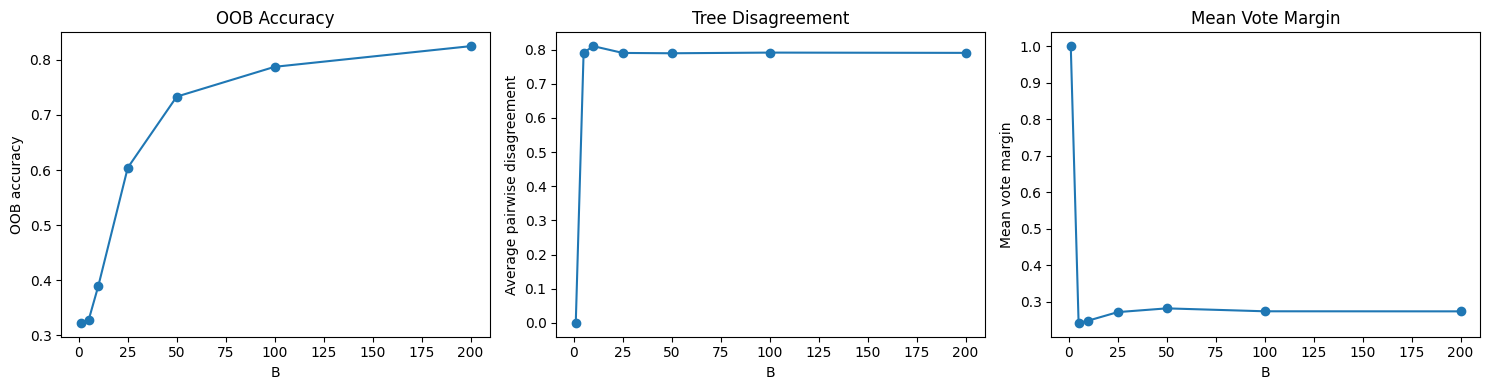

In [8]:
# Ploting
import os
import matplotlib.pyplot as plt

os.makedirs("figures", exist_ok=True)

plt.figure(figsize=(15, 4))

plt.subplot(1, 3, 1)
plt.plot(B_values, oob_accuracy, marker='o')
plt.xlabel("B")
plt.ylabel("OOB accuracy")
plt.title("OOB Accuracy")

plt.subplot(1, 3, 2)
plt.plot(B_values, disagreement, marker='o')
plt.xlabel("B")
plt.ylabel("Average pairwise disagreement")
plt.title("Tree Disagreement")

plt.subplot(1, 3, 3)
plt.plot(B_values, vote_margin, marker='o')
plt.xlabel("B")
plt.ylabel("Mean vote margin")
plt.title("Mean Vote Margin")

plt.tight_layout()
plt.savefig("figures/bagging_metrics.png", dpi=300, bbox_inches="tight") # save the figure
plt.show()

In [9]:
# Selecting the final ensemble using val accuracy

best_B = B_values[np.argmax([
    np.mean(majority_vote(np.array([
        tree.predict(X_val) for tree in trees[:B]
    ])) == y_val)
    for B in B_values
])]

print("Selected ensemble size:", best_B)

Selected ensemble size: 100



 Clean test set
Single tree accuracy: 0.5875
Single tree mean confidence: 1.0
Bagging accuracy: 0.85
Bagging mean confidence: 0.41600000000000004

 Masked test set
Single tree accuracy: 0.4125
Single tree mean confidence: 1.0
Bagging accuracy: 0.65
Bagging mean confidence: 0.274125

Test image index: 9
True identity: 0
Tree prediction: 25
Tree confidence: 1.0
Bagging prediction: 0
Bagging confidence: 0.3
Bagging vote counts: {0: 30, 3: 4, 4: 8, 7: 1, 9: 2, 11: 4, 15: 1, 16: 9, 21: 1, 22: 6, 25: 16, 26: 1, 27: 2, 35: 1, 36: 6, 37: 6, 39: 2}

Test image index: 6
True identity: 0
Tree prediction: 15
Tree confidence: 1.0
Bagging prediction: 0
Bagging confidence: 0.42
Bagging vote counts: {0: 42, 1: 2, 3: 5, 4: 1, 5: 1, 6: 1, 7: 4, 10: 1, 12: 1, 13: 2, 14: 1, 15: 16, 16: 3, 17: 3, 22: 1, 23: 6, 24: 2, 25: 2, 27: 1, 29: 1, 31: 2, 35: 1, 39: 1}

Test image index: 31
True identity: 3
Tree prediction: 30
Tree confidence: 1.0
Bagging prediction: 30
Bagging confidence: 0.27
Bagging vote counts: 

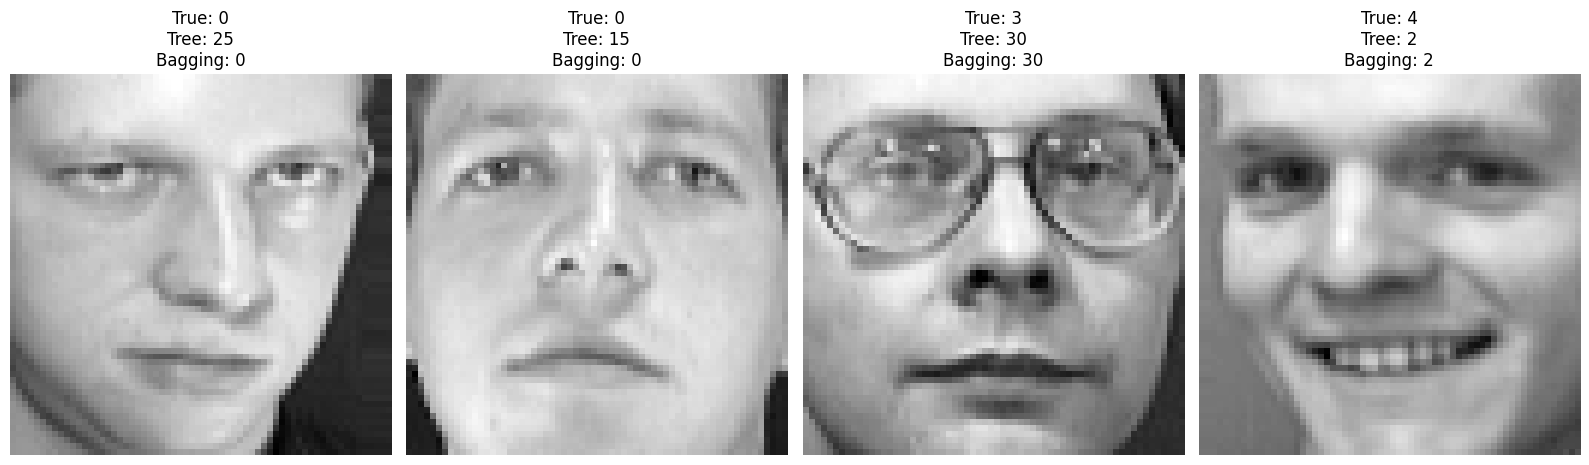

In [10]:
# Part(d)
# Comparing the single tree and bagging

os.makedirs("figures", exist_ok=True)

B_final = 100
final_trees = trees[:B_final]

X_test_clean = X[test_idx]
X_test_masked = X_test_clean.reshape(-1, 64, 64).copy()
X_test_masked[:, 24:40, 24:40] = 0
X_test_masked = X_test_masked.reshape(-1, 4096)


def bagging_predict(X_data):
    predictions = np.array([tree.predict(X_data) for tree in final_trees])
    vote_counts = np.zeros((len(X_data), 40), dtype=int)

    for i in range(len(X_data)):
        vote_counts[i] = np.bincount(predictions[:, i].astype(int), minlength=40)

    predictions = vote_counts.argmax(axis=1)
    confidence = vote_counts.max(axis=1) / B_final

    return predictions, confidence, vote_counts


def evaluate_models(X_data, y_data, name):
    tree_pred = frozen_tree.predict(X_data)
    tree_conf = frozen_tree.predict_proba(X_data).max(axis=1)

    bag_pred, bag_conf, vote_counts = bagging_predict(X_data)

    print("\n", name)
    print("Single tree accuracy:", np.mean(tree_pred == y_data))
    print("Single tree mean confidence:", np.mean(tree_conf))
    print("Bagging accuracy:", np.mean(bag_pred == y_data))
    print("Bagging mean confidence:", np.mean(bag_conf))

    return tree_pred, tree_conf, bag_pred, bag_conf, vote_counts


clean_results = evaluate_models(X_test_clean, y_test, "Clean test set")
masked_results = evaluate_models(X_test_masked, y_test, "Masked test set")


# Example faces using the clean test dataset

tree_pred, tree_conf, bag_pred, bag_conf, vote_counts = clean_results

corrected = np.where(
    (tree_pred != y_test) & (bag_pred == y_test)
)[0]

both_wrong = np.where(
    (tree_pred != y_test) & (bag_pred != y_test)
)[0]

examples = list(corrected[:2]) + list(both_wrong[:2])

for i in examples:
    votes = {
        identity: int(count)
        for identity, count in enumerate(vote_counts[i])
        if count > 0
    }

    print("\nTest image index:", int(test_idx[i]))
    print("True identity:", y_test[i])
    print("Tree prediction:", tree_pred[i])
    print("Tree confidence:", round(tree_conf[i], 4))
    print("Bagging prediction:", bag_pred[i])
    print("Bagging confidence:", round(bag_conf[i], 4))
    print("Bagging vote counts:", votes)

# Ploting and saving the example faces
fig, axes = plt.subplots(1, len(examples), figsize=(4 * len(examples), 5))

if len(examples) == 1:
    axes = [axes]

for ax, i in zip(axes, examples):
    ax.imshow(X_test_clean[i].reshape(64, 64), cmap="gray")
    ax.set_title(
        f"True: {y_test[i]}\n"
        f"Tree: {tree_pred[i]}\n"
        f"Bagging: {bag_pred[i]}"
    )
    ax.axis("off")

plt.tight_layout()
plt.savefig("figures/bagging_face_cases.png", dpi=300, bbox_inches="tight")
plt.show()

# Q2. Multiclass boosting from scratch

In [11]:
# Part (a): One SAMME round

from sklearn.tree import DecisionTreeClassifier

X_demo = np.arange(9).reshape(-1, 1)
y_demo = np.array([0, 0, 0, 1, 1, 1, 2, 2, 2])

K = 3
weights = np.ones(len(y_demo)) / len(y_demo)

print("Initial weights:", weights)

tree = DecisionTreeClassifier(max_depth=1, random_state=260008)
tree.fit(X_demo, y_demo, sample_weight=weights)

pred = tree.predict(X_demo)
error = np.sum(weights * (pred != y_demo))

print("Weak learner predictions:", pred)
print("Weighted error:", error)

if error >= 1 - 1 / K:
    print("Weak learner is no better than random. Stop.")
else:
    alpha = np.log((1 - error) / error) + np.log(K - 1)

    weights *= np.exp(alpha * (pred != y_demo))
    weights /= weights.sum()

    print("Alpha:", alpha)
    print("Updated weights:", weights)
    print("Weight sum:", weights.sum())

Initial weights: [0.11111111 0.11111111 0.11111111 0.11111111 0.11111111 0.11111111
 0.11111111 0.11111111 0.11111111]
Weak learner predictions: [0 0 0 1 1 1 1 1 1]
Weighted error: 0.3333333333333333
Alpha: 1.3862943611198908
Updated weights: [0.05555556 0.05555556 0.05555556 0.05555556 0.05555556 0.05555556
 0.22222222 0.22222222 0.22222222]
Weight sum: 1.0


Depth | Rounds | Validation accuracy
1 | 10 | 0.0375
1 | 25 | 0.05
1 | 50 | 0.05
1 | 100 | 0.1625
2 | 10 | 0.0875
2 | 25 | 0.0625
2 | 50 | 0.15
2 | 100 | 0.15
3 | 10 | 0.125
3 | 25 | 0.1125
3 | 50 | 0.2625
3 | 100 | 0.2375
4 | 10 | 0.1625
4 | 25 | 0.275
4 | 50 | 0.1875
4 | 100 | 0.2125

Selected depth: 4
Selected rounds: 25
Best validation accuracy: 0.275


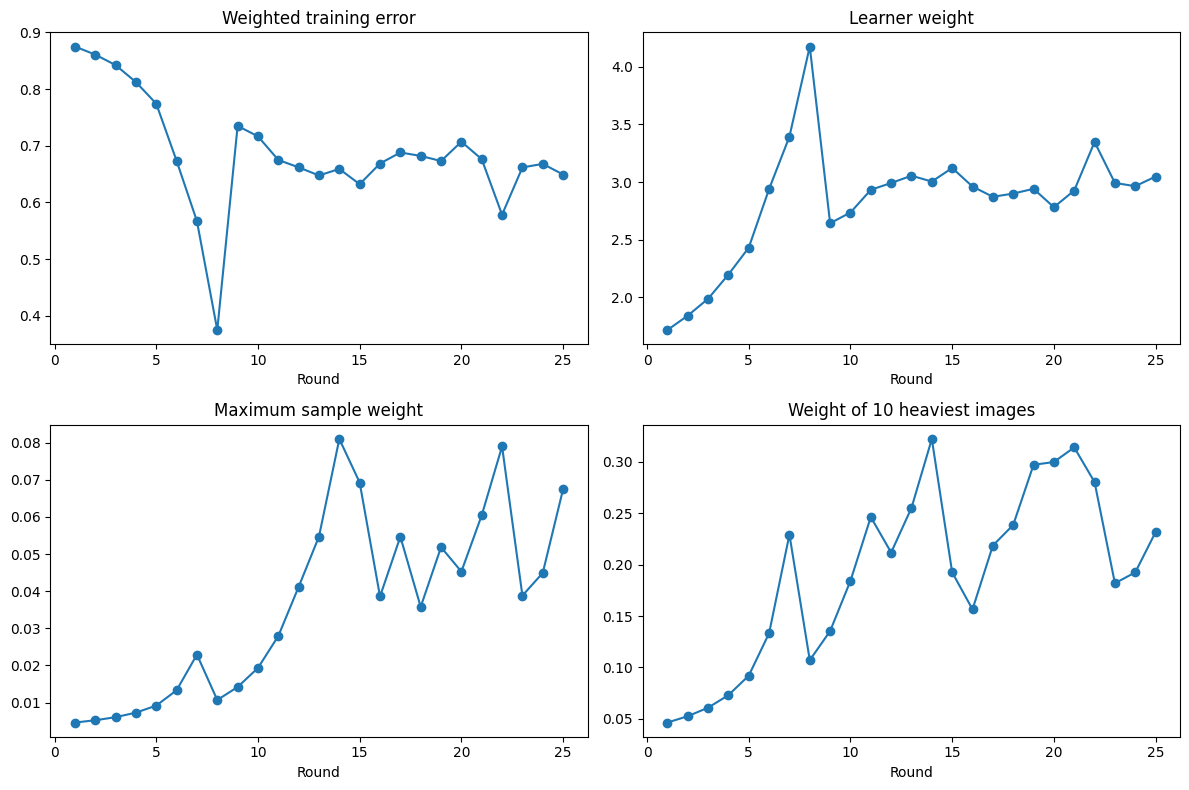

In [12]:
# Part (b): SAMME on Olivetti Faces
os.makedirs("figures", exist_ok=True)

depths = [1, 2, 3, 4]
rounds_list = [10, 25, 50, 100]
K = len(np.unique(y_train))

models = {}
results = []

for depth in depths:
    weights = np.ones(len(X_train)) / len(X_train)
    learners, alphas = [], []
    errors, max_weights, top10_weights = [], [], []

    for t in range(100):
        tree = DecisionTreeClassifier(
            max_depth=depth,
            random_state=260008 + t
        )
        tree.fit(X_train, y_train, sample_weight=weights)

        pred = tree.predict(X_train)
        error = np.sum(weights * (pred != y_train))

        if error >= 1 - 1 / K:
            break

        alpha = np.log((1 - error) / max(error, 1e-12)) + np.log(K - 1)

        learners.append(tree)
        alphas.append(alpha)
        errors.append(error)

        weights *= np.exp(alpha * (pred != y_train))
        weights /= weights.sum()

        max_weights.append(np.max(weights))
        top10_weights.append(np.sort(weights)[-10:].sum())

        if error <= 1e-12:
            break

        if len(learners) in rounds_list:
            scores = np.zeros((len(X_val), K))

            for model, a in zip(learners, alphas):
                pred_val = model.predict(X_val)
                scores[np.arange(len(X_val)), pred_val] += a

            val_acc = np.mean(np.argmax(scores, axis=1) == y_val)
            results.append((depth, len(learners), val_acc))

    models[depth] = {
        "learners": learners,
        "alphas": alphas,
        "errors": errors,
        "max_weights": max_weights,
        "top10_weights": top10_weights
    }

print("Depth | Rounds | Validation accuracy")
for depth, rounds, acc in results:
    print(depth, "|", rounds, "|", acc)

best_depth, best_rounds, best_val_acc = max(
    results, key=lambda x: x[2]
)

boost_depth_frozen = best_depth
boost_rounds_frozen = best_rounds

print("\nSelected depth:", boost_depth_frozen)
print("Selected rounds:", boost_rounds_frozen)
print("Best validation accuracy:", best_val_acc)


# Plot diagnostics for the selected model

selected = models[boost_depth_frozen]
T = boost_rounds_frozen

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

axes[0, 0].plot(range(1, T + 1), selected["errors"][:T], marker="o")
axes[0, 0].set_title("Weighted training error")
axes[0, 0].set_xlabel("Round")

axes[0, 1].plot(range(1, T + 1), selected["alphas"][:T], marker="o")
axes[0, 1].set_title("Learner weight")
axes[0, 1].set_xlabel("Round")

axes[1, 0].plot(range(1, T + 1), selected["max_weights"][:T], marker="o")
axes[1, 0].set_title("Maximum sample weight")
axes[1, 0].set_xlabel("Round")

axes[1, 1].plot(range(1, T + 1), selected["top10_weights"][:T], marker="o")
axes[1, 1].set_title("Weight of 10 heaviest images")
axes[1, 1].set_xlabel("Round")

plt.tight_layout()
plt.savefig("figures/adaboost_training_diagnostics.png",
            dpi=300, bbox_inches="tight")
plt.show()

Method | Learners | Train accuracy | Validation accuracy | Clean test accuracy | Training time (seconds)
Bagging | 25 | 1.0 | 0.8125 | 0.825 | 110.6282
Boosting | 25 | 0.6708 | 0.275 | 0.2875 | 36.9363
Bagging | 50 | 1.0 | 0.8125 | 0.825 | 224.104
Boosting | 50 | 0.5792 | 0.1875 | 0.1875 | 73.6583
Bagging | 100 | 1.0 | 0.85 | 0.85 | 443.1388
Boosting | 100 | 0.8583 | 0.2125 | 0.325 | 146.9565

Training image index: 6
True identity: 1
Final sample weight: 0.04228624709147097

Round | Prediction | Correct | Sample weight
1 | 0 | False | 0.004643
2 | 1 | True | 0.000833
3 | 2 | False | 0.000965
4 | 1 | True | 0.000128
5 | 4 | False | 0.000162
6 | 12 | False | 0.000234
7 | 14 | False | 0.000403
8 | 39 | False | 0.001049
9 | 2 | False | 0.001392
10 | 1 | True | 0.000123
11 | 3 | False | 0.000177
12 | 7 | False | 0.000261
13 | 12 | False | 0.000393
14 | 14 | False | 0.000582
15 | 22 | False | 0.000898
16 | 20 | False | 0.00131
17 | 1 | True | 0.000105
18 | 1 | True | 8e-06
19 | 36 | False | 

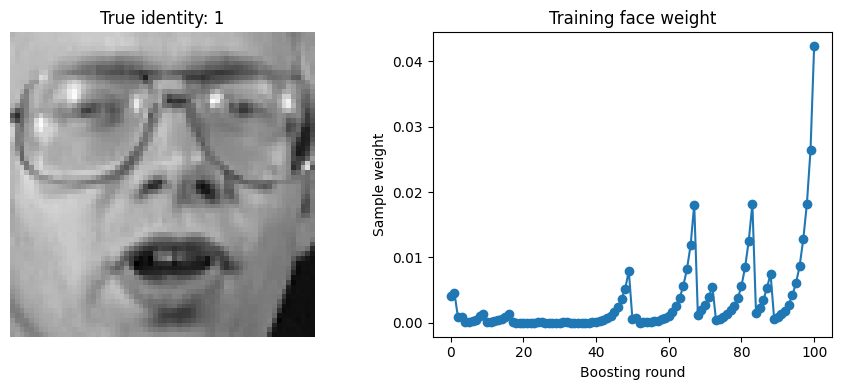

In [13]:
# Part (c): Compare bagging and boosting

import time
import matplotlib.pyplot as plt
import os

os.makedirs("figures", exist_ok=True)

B_values = [25, 50, 100]
K = len(np.unique(y_train))

# Train bagging models
rng = np.random.default_rng(260008)
bag_trees = []
bag_times = []

for b in range(100):
    idx = rng.choice(len(X_train), len(X_train), replace=True)

    tree = DecisionTreeClassifier(
        max_depth=tree_depth_frozen,
        min_samples_leaf=tree_min_leaf_frozen,
        random_state=260008 + b
    )

    start = time.perf_counter()
    tree.fit(X_train[idx], y_train[idx])
    bag_times.append(time.perf_counter() - start)
    bag_trees.append(tree)


# Train boosting models and save sample-weight history
weights = np.ones(len(X_train)) / len(X_train)
boost_trees = []
boost_alphas = []
boost_times = []
weight_history = [weights.copy()]
boost_predictions = []

for t in range(100):
    tree = DecisionTreeClassifier(max_depth=boost_depth_frozen, random_state=260008 + t)

    start = time.perf_counter()
    tree.fit(X_train, y_train, sample_weight=weights)
    elapsed = time.perf_counter() - start

    pred = tree.predict(X_train)
    error = np.sum(weights * (pred != y_train))

    if error >= 1 - 1 / K:
        break

    alpha = np.log((1 - error) / max(error, 1e-12)) + np.log(K - 1)

    boost_trees.append(tree)
    boost_alphas.append(alpha)
    boost_times.append(elapsed)
    boost_predictions.append(pred)

    weights *= np.exp(alpha * (pred != y_train))
    weights /= weights.sum()
    weight_history.append(weights.copy())

    if error <= 1e-12:
        break


def bag_predict(trees, X_data):
    pred = np.array([tree.predict(X_data) for tree in trees])
    return np.array([
        np.bincount(pred[:, i].astype(int), minlength=K).argmax()
        for i in range(pred.shape[1])
    ])


def boost_predict(trees, alphas, X_data):
    scores = np.zeros((len(X_data), K))

    for tree, alpha in zip(trees, alphas):
        pred = tree.predict(X_data).astype(int)
        scores[np.arange(len(X_data)), pred] += alpha

    return scores.argmax(axis=1)


print("Method | Learners | Train accuracy | Validation accuracy | "
      "Clean test accuracy | Training time (seconds)")

for B in B_values:
    if len(bag_trees) >= B:
        train_pred = bag_predict(bag_trees[:B], X_train)
        val_pred = bag_predict(bag_trees[:B], X_val)
        test_pred = bag_predict(bag_trees[:B], X_test)

        print(
            "Bagging |", B, "|",
            round(np.mean(train_pred == y_train), 4), "|",
            round(np.mean(val_pred == y_val), 4), "|",
            round(np.mean(test_pred == y_test), 4), "|",
            round(sum(bag_times[:B]), 4)
        )

    if len(boost_trees) >= B:
        train_pred = boost_predict(boost_trees[:B], boost_alphas[:B], X_train)
        val_pred = boost_predict(boost_trees[:B], boost_alphas[:B], X_val)
        test_pred = boost_predict(boost_trees[:B], boost_alphas[:B], X_test)

        print(
            "Boosting |", B, "|",
            round(np.mean(train_pred == y_train), 4), "|",
            round(np.mean(val_pred == y_val), 4), "|",
            round(np.mean(test_pred == y_test), 4), "|",
            round(sum(boost_times[:B]), 4)
        )


# Inspect the training face with the largest final boosting weight
face_idx = np.argmax(weight_history[-1])

print("\nTraining image index:", face_idx)
print("True identity:", y_train[face_idx])
print("Final sample weight:", weight_history[-1][face_idx])
print("\nRound | Prediction | Correct | Sample weight")

for t, pred in enumerate(boost_predictions):
    print(
        t + 1, "|",
        pred[face_idx], "|",
        pred[face_idx] == y_train[face_idx], "|",
        round(weight_history[t + 1][face_idx], 6)
    )


# Save the selected face and its weight history
fig, axes = plt.subplots(1, 2, figsize=(9, 4))

axes[0].imshow(X_train[face_idx].reshape(64, 64), cmap="gray")
axes[0].set_title(f"True identity: {y_train[face_idx]}")
axes[0].axis("off")

axes[1].plot(
    range(len(weight_history)),
    [w[face_idx] for w in weight_history],
    marker="o"
)
axes[1].set_xlabel("Boosting round")
axes[1].set_ylabel("Sample weight")
axes[1].set_title("Training face weight")

plt.tight_layout()
plt.savefig("figures/adaboost_high_weight_face.png",
            dpi=300, bbox_inches="tight")
plt.show()

Model | Test set | Accuracy | Mean winning confidence
Single tree | Clean | 0.5875 | 1.0
Bagging | Clean | 0.85 | 0.416
Boosting | Clean | 0.2875 | 0.1392
Single tree | Masked | 0.4125 | 1.0
Bagging | Masked | 0.65 | 0.2741
Boosting | Masked | 0.2 | 0.1392

Selected test image: 9
True identity: 0
Bagging clean prediction: 0
Bagging masked prediction: 0
Bagging clean vote counts: [30  4  8  1  2  4  1  9  1  6 16  1  2  1  6  6  2]
Bagging masked vote counts: [17  3  8  6  1  1  1  4  2  4  1  4  2  2  4  1  7  1 11  4  4  5  4  1
  2]
Boosting clean prediction: 12
Boosting masked prediction: 37
Boosting clean confidence: 0.12378158672244187
Boosting masked confidence: 0.14244622760987302
Bagging tree predictions, clean: [37 36 25  0 36  7  9  0 11 37  0  0 16 35  0 25  4 25  0  0  3  0  4  0
  3  0  0 37 11 22  0  4 25  3 25  0 25  0 22  0 25  0  0 37 22 16 16 25
  0  0 22 39  0  0  0 25  9 15 22 16 16 37 25  0  0 11 25  0 36  0 25  4
 27 25 25  4  0 36 37 26  0 36  0 21  4  3 16 22 27

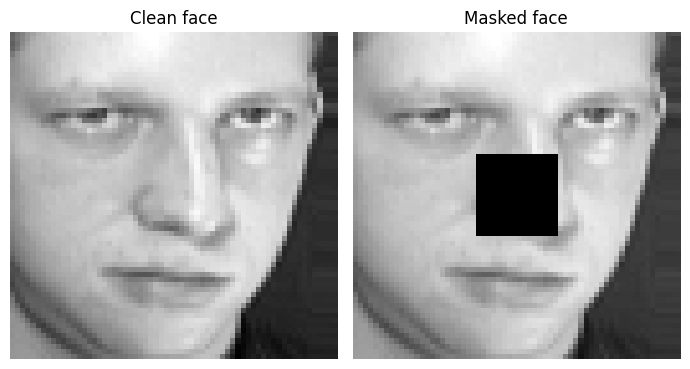


Highest-weight training image at round 25: 53
True identity: 8
Weight: 0.06746605172327319
Boosting predictions in rounds 1-25: [0, 1, 2, 3, 4, 12, 8, 39, 2, 1, 3, 7, 12, 14, 22, 20, 1, 8, 36, 12, 17, 14, 20, 39, 19]


In [14]:
# Part (d): Compare tree, bagging and boosting

import os
import matplotlib.pyplot as plt

os.makedirs("figures", exist_ok=True)

B_final = best_B
T_final = boost_rounds_frozen

final_bag_trees = bag_trees[:B_final]
final_boost_trees = boost_trees[:T_final]
final_boost_alphas = boost_alphas[:T_final]

X_test_clean = X[test_idx]
X_test_masked = X_test_clean.reshape(-1, 64, 64).copy()
X_test_masked[:, 24:40, 24:40] = 0
X_test_masked = X_test_masked.reshape(-1, 4096)


def get_predictions(X_data):
    tree_pred = frozen_tree.predict(X_data)
    tree_conf = frozen_tree.predict_proba(X_data).max(axis=1)

    bag_preds = np.array([
        tree.predict(X_data) for tree in final_bag_trees
    ])
    bag_votes = np.zeros((len(X_data), K), dtype=int)

    for i in range(len(X_data)):
        bag_votes[i] = np.bincount(
            bag_preds[:, i].astype(int), minlength=K
        )

    bag_pred = bag_votes.argmax(axis=1)
    bag_conf = bag_votes.max(axis=1) / B_final

    boost_scores = np.zeros((len(X_data), K))

    for tree, alpha in zip(final_boost_trees, final_boost_alphas):
        pred = tree.predict(X_data).astype(int)
        boost_scores[np.arange(len(X_data)), pred] += alpha

    boost_pred = boost_scores.argmax(axis=1)
    boost_conf = boost_scores.max(axis=1) / sum(final_boost_alphas)

    return (tree_pred, tree_conf, bag_pred, bag_conf,
            bag_preds, bag_votes, boost_pred, boost_conf, boost_scores)


clean = get_predictions(X_test_clean)
masked = get_predictions(X_test_masked)


print("Model | Test set | Accuracy | Mean winning confidence")

for name, results in [("Single tree", clean), ("Bagging", clean),
                      ("Boosting", clean)]:
    if name == "Single tree":
        pred, conf = results[0], results[1]
    elif name == "Bagging":
        pred, conf = results[2], results[3]
    else:
        pred, conf = results[6], results[7]

    print(name, "| Clean |",
          round(np.mean(pred == y_test), 4), "|",
          round(np.mean(conf), 4))

for name, results in [("Single tree", masked), ("Bagging", masked),
                      ("Boosting", masked)]:
    if name == "Single tree":
        pred, conf = results[0], results[1]
    elif name == "Bagging":
        pred, conf = results[2], results[3]
    else:
        pred, conf = results[6], results[7]

    print(name, "| Masked |",
          round(np.mean(pred == y_test), 4), "|",
          round(np.mean(conf), 4))


# Find a face where bagging and boosting react differently to masking

bag_changed = clean[2] != masked[2]
boost_changed = clean[6] != masked[6]

candidates = np.where(bag_changed != boost_changed)[0]

if len(candidates) == 0:
    candidates = np.where(masked[2] != masked[6])[0]

if len(candidates) > 0:
    i = candidates[0]

    print("\nSelected test image:", test_idx[i])
    print("True identity:", y_test[i])

    print("Bagging clean prediction:", clean[2][i])
    print("Bagging masked prediction:", masked[2][i])
    print("Bagging clean vote counts:",
          clean[5][i][clean[5][i] > 0])
    print("Bagging masked vote counts:",
          masked[5][i][masked[5][i] > 0])

    print("Boosting clean prediction:", clean[6][i])
    print("Boosting masked prediction:", masked[6][i])
    print("Boosting clean confidence:", clean[7][i])
    print("Boosting masked confidence:", masked[7][i])

    # Disagreement among bagged trees for this face
    print("Bagging tree predictions, clean:", clean[4][:, i])
    print("Bagging tree predictions, masked:", masked[4][:, i])

    fig, axes = plt.subplots(1, 2, figsize=(7, 4))
    axes[0].imshow(X_test_clean[i].reshape(64, 64), cmap="gray")
    axes[0].set_title("Clean face")
    axes[0].axis("off")

    axes[1].imshow(X_test_masked[i].reshape(64, 64), cmap="gray")
    axes[1].set_title("Masked face")
    axes[1].axis("off")

    plt.tight_layout()
    plt.savefig("figures/bagging_boosting_masked_face.png",
                dpi=300, bbox_inches="tight")
    plt.show()


# Inspect the highest-weight training image after 25 boosting rounds

weights_25 = weight_history[T_final]
hard_idx = np.argmax(weights_25)

print("\nHighest-weight training image at round 25:", hard_idx)
print("True identity:", y_train[hard_idx])
print("Weight:", weights_25[hard_idx])
print("Boosting predictions in rounds 1-25:",
      [int(pred[hard_idx]) for pred in boost_predictions[:T_final]])

In [15]:
# Q3(a): Bias, variance and test accuracy

from sklearn.tree import DecisionTreeClassifier
from joblib import Parallel, delayed

K = 40
R = 30
B = best_B

def get_probabilities(model, X_data):
    p = np.zeros((len(X_data), K))
    p[:, model.classes_.astype(int)] = model.predict_proba(X_data)
    return p


def run_repetition(r):
    rng = np.random.default_rng(260008 + r)

    # Sample six training images with replacement within each identity
    idx = np.concatenate([
        rng.choice(np.where(y_train == c)[0], 6, replace=True)
        for c in np.unique(y_train)
    ])
    Xr, yr = X_train[idx], y_train[idx]

    # Single tree
    tree = DecisionTreeClassifier(
        max_depth=tree_depth_frozen, min_samples_leaf=tree_min_leaf_frozen,
        random_state=260008 + r
    )
    tree.fit(Xr, yr)
    p_tree = get_probabilities(tree, X_test)

    # Bagging
    bag_votes = np.zeros((len(X_test), K))

    for b in range(B):
        sample = rng.choice(len(Xr), len(Xr), replace=True)
        tree = DecisionTreeClassifier(
            max_depth=tree_depth_frozen, min_samples_leaf=tree_min_leaf_frozen,
            random_state=260008 + r * B + b
        )
        tree.fit(Xr[sample], yr[sample])
        pred = tree.predict(X_test).astype(int)
        bag_votes[np.arange(len(X_test)), pred] += 1 / B

    # SAMME boosting
    weights = np.ones(len(Xr)) / len(Xr)
    scores = np.zeros((len(X_test), K))
    alpha_sum = 0

    for t in range(boost_rounds_frozen):
        tree = DecisionTreeClassifier(
            max_depth=boost_depth_frozen, random_state=260008 + r * boost_rounds_frozen + t
        )
        tree.fit(Xr, yr, sample_weight=weights)

        pred_train = tree.predict(Xr)
        error = np.sum(weights * (pred_train != yr))

        if error >= 1 - 1 / K:
            break

        alpha = np.log((1 - error) / max(error, 1e-12)) + np.log(K - 1)

        pred_test = tree.predict(X_test).astype(int)
        scores[np.arange(len(X_test)), pred_test] += alpha
        alpha_sum += alpha

        weights *= np.exp(alpha * (pred_train != yr))
        weights /= weights.sum()

        if error <= 1e-12:
            break

    p_boost = scores / alpha_sum

    return p_tree, bag_votes, p_boost


# Run the 30 repetitions using two CPU workers
results = Parallel(n_jobs=2)(
    delayed(run_repetition)(r) for r in range(R)
)

tree_probs = np.array([result[0] for result in results])
bag_probs = np.array([result[1] for result in results])
boost_probs = np.array([result[2] for result in results])


def measure_bias_variance(probabilities):
    mean_p = probabilities.mean(axis=0)

    target = np.zeros((len(y_test), K))
    target[np.arange(len(y_test)), y_test.astype(int)] = 1

    bias_squared = np.mean(np.sum((mean_p - target) ** 2, axis=1))
    variance = np.mean(np.sum((probabilities - mean_p) ** 2, axis=2))

    predictions = probabilities.argmax(axis=2)
    accuracies = np.mean(predictions == y_test, axis=1)

    return bias_squared, variance, accuracies.mean(), accuracies.std()


print("Model | Bias squared | Variance | Mean test accuracy | Std test accuracy")

for name, probabilities in [
    ("Single tree", tree_probs),
    ("Bagging", bag_probs),
    ("Boosting", boost_probs)
]:
    bias, variance, mean_acc, std_acc = measure_bias_variance(probabilities)

    print(
        name, "|",
        round(bias, 4), "|",
        round(variance, 4), "|",
        round(mean_acc, 4), "|",
        round(std_acc, 4)
    )

np.savez(
    "q3_bias_variance_results.npz",
    tree_probs=tree_probs,
    bag_probs=bag_probs,
    boost_probs=boost_probs
)

Model | Bias squared | Variance | Mean test accuracy | Std test accuracy
Single tree | 0.373 | 0.6403 | 0.4933 | 0.0456
Bagging | 0.4934 | 0.0243 | 0.7888 | 0.0282
Boosting | 0.8855 | 0.0307 | 0.2125 | 0.0766


In [16]:
# Q3(b): Effect of tree depth on bias and variance

from joblib import Parallel, delayed
from sklearn.tree import DecisionTreeClassifier

depths = [2, 8, tree_depth_frozen]
B = best_B
R = 30
K = 40


def class_probs(model, X_data):
    p = np.zeros((len(X_data), K))
    p[:, model.classes_.astype(int)] = model.predict_proba(X_data)
    return p


def run_depth_experiment(r):
    rng = np.random.default_rng(260008 + r)

    # Resample six training images within each identity
    idx = np.concatenate([
        rng.choice(np.where(y_train == c)[0], 6, replace=True)
        for c in np.unique(y_train)
    ])

    Xr, yr = X_train[idx], y_train[idx]
    repetition_results = {}

    for depth in depths:
        # Single tree
        tree = DecisionTreeClassifier(
            max_depth=depth, min_samples_leaf=1,
            random_state=260008 + r
        )
        tree.fit(Xr, yr)

        single_p = class_probs(tree, X_test)
        single_acc = np.mean(tree.predict(X_test) == y_test)

        # Bagging with 100 trees
        rng_bag = np.random.default_rng(260008 + r * 1000 + (depth or 0))
        bag_p = np.zeros((len(X_test), K))

        for b in range(B):
            sample = rng_bag.choice(len(Xr), len(Xr), replace=True)

            bag_tree = DecisionTreeClassifier(
                max_depth=depth, min_samples_leaf=1,
                random_state=260008 + r * B + b
            )
            bag_tree.fit(Xr[sample], yr[sample])

            pred = bag_tree.predict(X_test).astype(int)
            bag_p[np.arange(len(X_test)), pred] += 1 / B

        bag_acc = np.mean(bag_p.argmax(axis=1) == y_test)

        repetition_results[depth] = (
            single_p, bag_p, single_acc, bag_acc
        )

    return repetition_results


results = Parallel(n_jobs=2)(
    delayed(run_depth_experiment)(r) for r in range(R)
)


# Calculate bias squared, variance and accuracy statistics

target = np.zeros((len(y_test), K))
target[np.arange(len(y_test)), y_test.astype(int)] = 1

print("Depth | Model | Bias squared | Variance | Mean accuracy | Std accuracy")

for depth in depths:
    for model_name, position in [("Single tree", 0), ("Bagging", 1)]:
        probabilities = np.array([
            results[r][depth][position] for r in range(R)
        ])

        mean_p = probabilities.mean(axis=0)
        bias_squared = np.mean(np.sum((mean_p - target) ** 2, axis=1))
        variance = np.mean(np.sum((probabilities - mean_p) ** 2, axis=2))

        accuracies = np.array([
            results[r][depth][position + 2] for r in range(R)
        ])

        print(
            depth, "|", model_name, "|",
            round(bias_squared, 4), "|",
            round(variance, 4), "|",
            round(accuracies.mean(), 4), "|",
            round(accuracies.std(), 4)
        )

    single_var = np.mean(np.sum(
        (np.array([results[r][depth][0] for r in range(R)])
         - np.array([results[r][depth][0] for r in range(R)]).mean(axis=0)) ** 2,
        axis=2
    ))

    bag_probs = np.array([results[r][depth][1] for r in range(R)])
    bag_var = np.mean(np.sum(
        (bag_probs - bag_probs.mean(axis=0)) ** 2, axis=2
    ))

    print("Variance removed by bagging:", round(single_var - bag_var, 4))
    print()

Depth | Model | Bias squared | Variance | Mean accuracy | Std accuracy
2 | Single tree | 0.9112 | 0.0388 | 0.0612 | 0.0126
2 | Bagging | 0.9315 | 0.0098 | 0.155 | 0.061
Variance removed by bagging: 0.029

8 | Single tree | 0.7722 | 0.138 | 0.1633 | 0.0343
8 | Bagging | 0.8019 | 0.0162 | 0.4762 | 0.0688
Variance removed by bagging: 0.1218

None | Single tree | 0.373 | 0.6403 | 0.4933 | 0.0456
None | Bagging | 0.4918 | 0.0245 | 0.7883 | 0.0402
Variance removed by bagging: 0.6159



In [17]:
# Q3(c): Leaf occupancy and tree disagreement

depths = [2, 8, tree_depth_frozen]
B = best_B

rng = np.random.default_rng(260008)
idx = np.concatenate([
    rng.choice(np.where(y_train == c)[0], 6, replace=True)
    for c in np.unique(y_train)
])

Xr, yr = X_train[idx], y_train[idx]

print("Depth | Mean leaf samples | Singleton fraction | Disagreement")

for depth in depths:
    tree = DecisionTreeClassifier(
        max_depth=depth,
        min_samples_leaf=1,
        random_state=260008
    )
    tree.fit(Xr, yr)

    leaf_ids = np.where(tree.tree_.children_left == -1)[0]
    leaf_samples = tree.tree_.n_node_samples[leaf_ids]

    mean_leaf_samples = np.mean(leaf_samples)
    singleton_fraction = np.mean(leaf_samples == 1)

    rng_bag = np.random.default_rng(260008)
    predictions = []

    for b in range(B):
        sample = rng_bag.choice(len(Xr), len(Xr), replace=True)

        model = DecisionTreeClassifier(
            max_depth=depth,
            min_samples_leaf=1,
            random_state=260008 + b
        )
        model.fit(Xr[sample], yr[sample])
        predictions.append(model.predict(X_test))

    predictions = np.array(predictions)
    disagreements = []

    for i in range(B):
        for j in range(i + 1, B):
            disagreements.append(
                np.mean(predictions[i] != predictions[j])
            )

    print(
        depth, "|",
        round(mean_leaf_samples, 4), "|",
        round(singleton_fraction, 4), "|",
        round(np.mean(disagreements), 4)
    )

Depth | Mean leaf samples | Singleton fraction | Disagreement
2 | 80.0 | 0.0 | 0.9637
8 | 26.6667 | 0.0 | 0.9253
None | 6.0 | 0.0 | 0.8147


In [18]:
# Q3(d): Final comparison

# Create masked test set
X_test_masked = X_test.reshape(-1, 64, 64).copy()
X_test_masked[:, 24:40, 24:40] = 0
X_test_masked = X_test_masked.reshape(-1, 4096)

# Frozen models
final_bag_trees = bag_trees[:best_B]
final_boost_trees = boost_trees[:boost_rounds_frozen]
final_boost_alphas = boost_alphas[:boost_rounds_frozen]

K = 40


def bag_predict(X_data):
    pred = np.array([tree.predict(X_data) for tree in final_bag_trees])
    return np.array([
        np.bincount(pred[:, i].astype(int), minlength=K).argmax()
        for i in range(len(X_data))
    ])


def boost_predict(X_data):
    scores = np.zeros((len(X_data), K))

    for tree, alpha in zip(final_boost_trees, final_boost_alphas):
        pred = tree.predict(X_data).astype(int)
        scores[np.arange(len(X_data)), pred] += alpha

    return scores.argmax(axis=1)


models = {
    "Single tree": (
        frozen_tree.predict(X_test),
        frozen_tree.predict(X_test_masked)
    ),
    "Bagging": (
        bag_predict(X_test),
        bag_predict(X_test_masked)
    ),
    "Boosting": (
        boost_predict(X_test),
        boost_predict(X_test_masked)
    )
}

# Bias squared and variance from the 30 refits in Q3(a)
probabilities = {
    "Single tree": tree_probs,
    "Bagging": bag_probs,
    "Boosting": boost_probs
}

target = np.zeros((len(y_test), K))
target[np.arange(len(y_test)), y_test.astype(int)] = 1

print("Model | Clean accuracy | Masked accuracy | Bias squared | Variance")

for name, (clean_pred, masked_pred) in models.items():
    p = probabilities[name]
    mean_p = p.mean(axis=0)

    bias_squared = np.mean(np.sum((mean_p - target) ** 2, axis=1))
    variance = np.mean(np.sum((p - mean_p) ** 2, axis=2))

    print(
        name, "|",
        round(np.mean(clean_pred == y_test), 4), "|",
        round(np.mean(masked_pred == y_test), 4), "|",
        round(bias_squared, 4), "|",
        round(variance, 4)
    )

Model | Clean accuracy | Masked accuracy | Bias squared | Variance
Single tree | 0.5875 | 0.4125 | 0.373 | 0.6403
Bagging | 0.85 | 0.65 | 0.4918 | 0.0245
Boosting | 0.2875 | 0.2 | 0.8855 | 0.0307
